# Capítulo 5 · Random Forest: clasificar y predecir un número

**Aprendizaje supervisado · Uso de Random Forest**

Un árbol toma decisiones con preguntas sobre las columnas. Un **Random Forest** entrena muchos árboles y combina sus respuestas.

- Cada árbol recibe una muestra aleatoria de las filas de entrenamiento, **con reemplazo**: algunas se repiten y otras quedan fuera. Esto se llama *bootstrap*.
- En cada división se consideran columnas al azar, según `max_features`, para que los árboles no sean todos iguales.
- **Clasificación (`RandomForestClassifier`):** promedia las probabilidades de los árboles y elige la clase con mayor probabilidad.
- **Regresión (`RandomForestRegressor`):** promedia los números predichos por los árboles.

Combinar árboles suele reducir la variación de un árbol individual, aunque el bosque también puede sobreajustar. Como usa cortes por columna, **no necesita estandarizar** las variables.

### 📚 Índice
1. Iris: un vistazo y clasificar
2. Autos: un vistazo y predecir millas por galón
3. Chuleta resumen

Usamos los mismos datos y particiones que en la 07. Los archivos `iris.csv` y `mpg.csv` deben estar en `data/`; si faltan, ejecuta `uv run python scripts/download_data.py` desde la raíz del repositorio.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import confusion_matrix, classification_report, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

sns.set_theme(style="whitegrid")
palette = sns.color_palette("deep")

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = raiz / "data"

---
## 1. Iris: un vistazo y clasificar

Las mismas 150 flores. Con el largo y el ancho del pétalo ya se ve por qué una frontera puede separar las especies.


In [2]:
iris = pd.read_csv(DATA_DIR / "iris.csv")
especies = ["setosa", "versicolor", "virginica"]
iris.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Cómo se ve

50 flores de cada especie. La setosa queda aparte en el pétalo; versicolor y virginica se tocan. El largo y el ancho del pétalo van casi juntos.


In [3]:
iris["target"].map(dict(enumerate(especies))).value_counts().rename("flores")


target
setosa        50
versicolor    50
virginica     50
Name: flores, dtype: int64

In [4]:
iris.drop(columns="target").describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


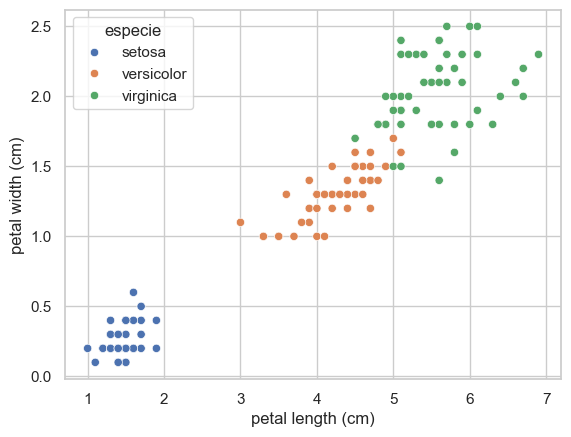

In [5]:
iris_plot = iris.assign(especie=iris["target"].map(dict(enumerate(especies))))
sns.scatterplot(
    data=iris_plot, x="petal length (cm)", y="petal width (cm)",
    hue="especie", palette=palette[:3]
)
plt.show()


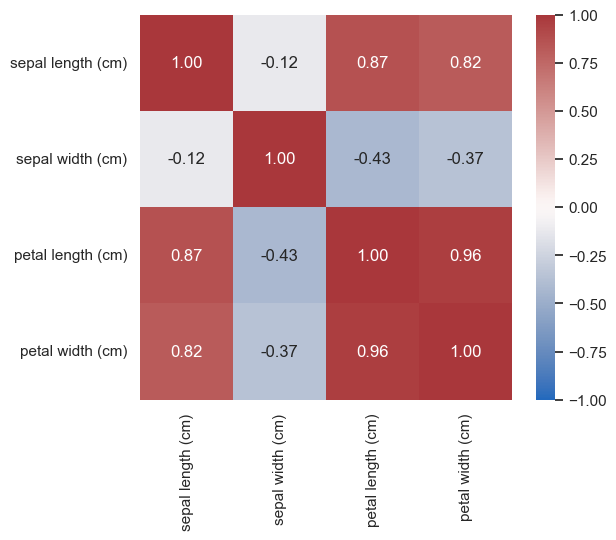

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    iris.drop(columns="target").corr(), annot=True, fmt=".2f",
    cmap="vlag", center=0, vmin=-1, vmax=1
)
plt.show()


Con solo el pétalo podemos dibujar la frontera del bosque. El fondo muestra la clase predicha y los puntos, las especies reales. Los cortes de los árboles producen regiones escalonadas. Entrenamos con train; la accuracy se calcula con test.

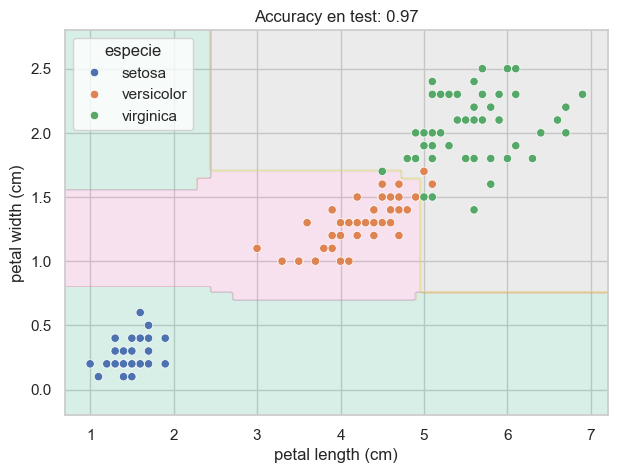

In [7]:
X_petalo = iris[["petal length (cm)", "petal width (cm)"]]
y = iris["target"]
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_petalo, y, test_size=0.2, random_state=42, stratify=y
)

bosque_petalo = RandomForestClassifier(
    n_estimators=100, max_depth=3, random_state=42,
)
bosque_petalo.fit(X_train_p, y_train_p)

largo = np.linspace(X_petalo.iloc[:, 0].min() - 0.3, X_petalo.iloc[:, 0].max() + 0.3, 200)
ancho = np.linspace(X_petalo.iloc[:, 1].min() - 0.3, X_petalo.iloc[:, 1].max() + 0.3, 200)
xx, yy = np.meshgrid(largo, ancho)
malla = pd.DataFrame({
    "petal length (cm)": xx.ravel(),
    "petal width (cm)": yy.ravel(),
})
zz = bosque_petalo.predict(malla).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.25, cmap="Set2")
sns.scatterplot(
    data=iris_plot, x="petal length (cm)", y="petal width (cm)",
    hue="especie", palette=palette[:3]
)
plt.title(f"Accuracy en test: {bosque_petalo.score(X_test_p, y_test_p):.2f}")
plt.show()

### Un árbol frente a un bosque

Ahora usamos las cuatro medidas de la flor. Comparamos un árbol y un bosque con la misma partición. Una accuracy alta en train y menor en test puede indicar sobreajuste. En un dataset pequeño no está garantizado que el bosque gane.

Esta comparación es ilustrativa: elegiremos los hiperparámetros con validación cruzada sobre train, sin usar test para decidir.

In [8]:
X = iris.drop(columns="target")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y,
)

filas = []
for nombre, modelo in {
    "Árbol": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}.items():
    modelo.fit(X_train, y_train)
    filas.append({
        "modelo": nombre,
        "accuracy_train": modelo.score(X_train, y_train),
        "accuracy_test": modelo.score(X_test, y_test),
    })

pd.DataFrame(filas).round(3)

,modelo,accuracy_train,accuracy_test
0,Árbol,1.0,0.933
1,Random Forest,1.0,0.900


### Elegir la profundidad y el tamaño de las hojas

`n_estimators` es la cantidad de árboles; dejamos 100 para que el ejemplo sea rápido. `max_depth` limita la profundidad y `min_samples_leaf` exige un mínimo de ejemplos por hoja. Son formas de controlar cuánto detalle aprende cada árbol.

`GridSearchCV` prueba combinaciones con cinco particiones de train y elige la mayor accuracy media. `max_features="sqrt"` considera la raíz cuadrada del número de columnas en cada división: con cuatro columnas, considera dos. Fijamos `random_state=42` para repetir el resultado.

In [9]:
modelo_base = RandomForestClassifier(
    n_estimators=100, max_features="sqrt", random_state=42
)

rejilla = {
    "max_depth": [3, None],
    "min_samples_leaf": [1, 3, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

busqueda = GridSearchCV(modelo_base, rejilla, cv=cv, scoring="accuracy")
busqueda.fit(X_train, y_train)
print(busqueda.best_params_)
print(f"Accuracy CV:   {busqueda.best_score_:.3f}")
print(f"Accuracy test: {busqueda.score(X_test, y_test):.3f}")

{'max_depth': 3, 'min_samples_leaf': 5}
Accuracy CV:   0.967
Accuracy test: 0.933


### Reporte de clasificación y matriz de confusión

La accuracy resume los aciertos; el reporte permite revisar cada especie usando las predicciones del modelo elegido por validación cruzada sobre **test**.

- **Precision:** de las flores predichas como una especie, qué proporción era de esa especie.
- **Recall:** de las flores que realmente eran de una especie, qué proporción encontramos.
- **F1-score:** combina precision y recall mediante su media armónica.
- **Support:** cuántas flores reales hay de cada especie en test.

`macro avg` da el mismo peso a cada especie; `weighted avg` pondera por su cantidad de flores.
En la matriz, las filas son clases reales y las columnas son predicciones. La diagonal contiene los aciertos; fuera de ella aparecen las confusiones. Test sirve para evaluar, no para seguir ajustando hiperparámetros.


In [10]:
y_pred = busqueda.predict(X_test)
print(classification_report(
    y_test, y_pred, labels=[0, 1, 2], target_names=especies,
    digits=3, zero_division=0,
))


              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



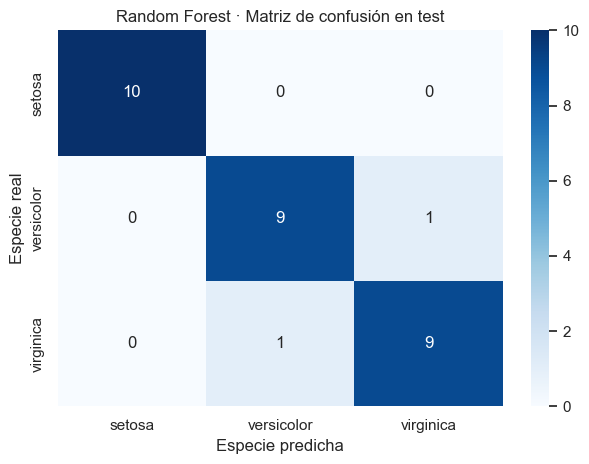

In [11]:
matriz = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=especies, yticklabels=especies,
)
plt.title("Random Forest · Matriz de confusión en test")
plt.xlabel("Especie predicha")
plt.ylabel("Especie real")
plt.tight_layout()
plt.show()


### Qué columnas usa más el bosque

`feature_importances_` resume cuánto ayudó cada columna a reducir la impureza en los árboles durante el entrenamiento. Las importancias suman 1. Sirven como orientación, **no demuestran causalidad**: pueden favorecer columnas con muchos valores distintos y repartirse entre columnas correlacionadas.

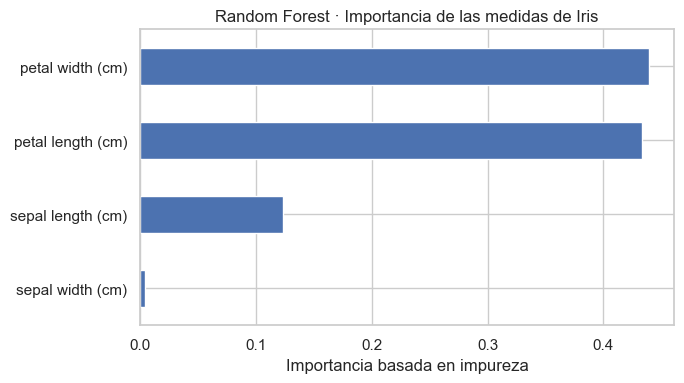

In [12]:
importancias = pd.Series(
    busqueda.best_estimator_.feature_importances_, index=X.columns,
).sort_values()
importancias.plot.barh(figsize=(7, 4), color=palette[0])
plt.title("Random Forest · Importancia de las medidas de Iris")
plt.xlabel("Importancia basada en impureza")
plt.tight_layout()
plt.show()

---
## 2. Autos: un vistazo y predecir millas por galón

`RandomForestRegressor` sigue los mismos pasos, pero promedia predicciones numéricas. Vamos a predecir `mpg`: más millas por galón significa recorrer más distancia con la misma cantidad de combustible.

### Cómo se ve

398 autos y 6 sin `horsepower`. Revisamos nulos y distribuciones antes de entrenar. A más peso suele haber menos millas por galón. Aquí las escalas distintas de peso y año no requieren `StandardScaler`.

In [13]:
autos = pd.read_csv(DATA_DIR / "mpg.csv")
autos.head()


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\robof\\OneDrive\\AprendiendoNumpyPandas\\ml-course\\ml-course-2026\\data\\mpg.csv'

In [ ]:
autos.isna().sum().rename("nulos")


In [ ]:
autos.describe()


In [ ]:
sns.histplot(data=autos, x="mpg", bins=20, color=palette[0])
plt.show()


In [ ]:
sns.scatterplot(data=autos, x="weight", y="mpg", color=palette[0], alpha=0.7)
plt.show()


In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(autos.corr(numeric_only=True), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.show()


### Del árbol al promedio de árboles

Primero usamos solo el peso para dibujar las predicciones. Un árbol produce escalones; al promediar muchos árboles, el bosque suele hacerlos menos bruscos. Ninguno extrapola bien fuera del rango observado: las predicciones son promedios de valores aprendidos.

In [ ]:
autos = autos.dropna(subset=["mpg", "weight", "horsepower", "model_year"])
X_peso = autos[["weight"]]
y_mpg = autos["mpg"]
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_peso, y_mpg, test_size=0.2, random_state=42,
)

pesos = np.linspace(autos["weight"].min(), autos["weight"].max(), 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
modelos = {
    "Árbol": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
}
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    modelo.fit(X_train_w, y_train_w)
    curva = modelo.predict(pd.DataFrame({"weight": pesos}))
    sns.scatterplot(data=autos, x="weight", y="mpg", color=palette[0], alpha=0.35, ax=ax)
    ax.plot(pesos, curva, color=palette[1], linewidth=2)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

### Usar peso, potencia y año

Comparamos ambos modelos con tres columnas. **RMSE** expresa el error en millas por galón: menor es mejor. **R²** vale 1 para predicciones perfectas, 0 para predecir siempre la media de los valores reales evaluados y puede ser negativo.

Mirar train y test ayuda a detectar sobreajuste. En regresión no usamos reporte de clasificación ni matriz de confusión, porque la respuesta es un número continuo.

In [ ]:
columnas = ["weight", "horsepower", "model_year"]
X_auto = autos[columnas]
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_auto, y_mpg, test_size=0.2, random_state=42,
)

filas = []
for nombre, modelo in {
    "Árbol": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}.items():
    modelo.fit(X_train_a, y_train_a)
    pred = modelo.predict(X_test_a)
    filas.append({
        "modelo": nombre,
        "R2_train": modelo.score(X_train_a, y_train_a),
        "R2_test": modelo.score(X_test_a, y_test_a),
        "RMSE_test": root_mean_squared_error(y_test_a, pred),
    })

pd.DataFrame(filas).round(3)

### Elegir hiperparámetros con validación cruzada

Buscamos profundidad y tamaño de hoja con `KFold`. El criterio es el R² medio de validación. En este ejemplo, `max_features=1.0` permite considerar todas las columnas en cada división; el bootstrap sigue haciendo diferentes a los árboles.

Una vez elegida la combinación, evaluamos en test. No cambiamos los parámetros para intentar mejorar ese resultado.

In [ ]:
modelo_base_reg = RandomForestRegressor(
    n_estimators=100, max_features=1.0, random_state=42
)

rejilla_reg = {
    "max_depth": [5, None],
    "min_samples_leaf": [1, 3, 5],
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

busqueda_reg = GridSearchCV(modelo_base_reg, rejilla_reg, cv=cv_reg, scoring="r2")
busqueda_reg.fit(X_train_a, y_train_a)
pred_reg = busqueda_reg.predict(X_test_a)
print(busqueda_reg.best_params_)
print(f"R² CV:     {busqueda_reg.best_score_:.3f}")
print(f"R² test:   {busqueda_reg.score(X_test_a, y_test_a):.3f}")
print(f"RMSE test: {root_mean_squared_error(y_test_a, pred_reg):.3f} mpg")

---
## 3. 📋 Chuleta resumen

| Tarea | Código |
|---|---|
| Clasificar | `RandomForestClassifier(random_state=42)` |
| Predecir un número | `RandomForestRegressor(random_state=42)` |
| Número de árboles | `n_estimators=100` |
| Limitar profundidad | `max_depth=5` |
| Mínimo de ejemplos por hoja | `min_samples_leaf=3` |
| Columnas candidatas en cada división | `max_features="sqrt"` o `max_features=1.0` |
| Reporte por especie | `classification_report(y_test, y_pred, target_names=especies)` |
| Matriz de confusión | `sns.heatmap(matriz, annot=True, fmt="d")` |
| Error de regresión | `root_mean_squared_error(y_test_a, pred_reg)` |
| Elegir hiperparámetros | `GridSearchCV(modelo_base, rejilla, cv=cv)` |

> 💡 Más árboles suelen estabilizar el promedio, pero tardan más y no garantizan mejorar la accuracy. La profundidad y el tamaño de hoja controlan la complejidad de cada árbol. Elige con validación cruzada y reserva test para evaluar.

Documentación: [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html), [reporte de clasificación](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html).